In [21]:
#1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

In [22]:
df = pd.read_csv("classification_escalation.csv")

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


In [23]:
#2
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Counts:")
print(df["escalated"].value_counts())

print("\nTarget Proportions:")
print(df["escalated"].value_counts(normalize=True))

Dataset Shape:
(900, 6)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB

Missing Values:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Target Counts:
escalated
0    714
1    186
Name: count, dtype: int64

Target Proportions:
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


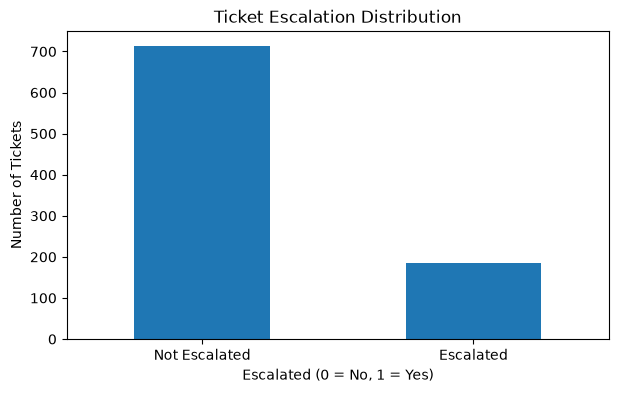

In [24]:
#4
df["escalated"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Ticket Escalation Distribution")
plt.xlabel("Escalated (0 = No, 1 = Yes)")
plt.ylabel("Number of Tickets")
plt.xticks([0, 1], ["Not Escalated", "Escalated"], rotation=0)
plt.show()

In [25]:
#5
X = df.drop("escalated", axis=1)

y = df["escalated"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,complexity_score,team_experience_years,priority,channel,customer_tenure_months
0,9,7.7,low,web,21.6
1,2,6.1,high,web,21.8
2,1,2.5,medium,phone,28.8
3,7,5.3,low,email,52.5
4,4,7.1,medium,email,14.7



Target:


0    0
1    0
2    0
3    0
4    0
Name: escalated, dtype: int64

In [26]:
#6
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (675, 5)
Testing Features: (225, 5)

Training Target Distribution:
escalated
0    535
1    140
Name: count, dtype: int64

Testing Target Distribution:
escalated
0    179
1     46
Name: count, dtype: int64


In [27]:
#7
numeric_features = [
    "complexity_score",
    "team_experience_years",
    "customer_tenure_months"
]

categorical_features = [
    "priority",
    "channel"
]

print("Numeric Features:", numeric_features)

print("Categorical Features:", categorical_features)

Numeric Features: ['complexity_score', 'team_experience_years', 'customer_tenure_months']
Categorical Features: ['priority', 'channel']


In [28]:
#8
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing completed!")

Preprocessing completed!


In [29]:
#9
models = {
    "Majority Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Linear Discriminant Analysis": LinearDiscriminantAnalysis(),

    "k-NN (k=15)": KNeighborsClassifier(
        n_neighbors=15
    )
}

print("All four models created successfully!")

All four models created successfully!


In [30]:
#10
results = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predict classes
    y_pred = pipeline.predict(X_test)

    # Predict probabilities
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": auc
    })

    trained_models[name] = pipeline

# Comparison table
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,Linear Discriminant Analysis,0.8222,0.75,0.1957,0.3103,0.8090
3,k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


In [31]:
#11
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

for metric in metrics:

    best_index = results_df[metric].idxmax()

    print("\nHighest", metric)

    print(results_df.loc[
        best_index, ["Model", metric]
    ])


Highest Accuracy
Model       Logistic Regression
Accuracy               0.822222
Name: 1, dtype: object

Highest Precision
Model        Logistic Regression
Precision                   0.75
Name: 1, dtype: object

Highest Recall
Model     Logistic Regression
Recall               0.195652
Name: 1, dtype: object

Highest F1
Model    Logistic Regression
F1                  0.310345
Name: 1, dtype: object

Highest ROC-AUC
Model      Logistic Regression
ROC-AUC               0.811149
Name: 1, dtype: object


Confusion Matrix:
[[176   3]
 [ 37   9]]


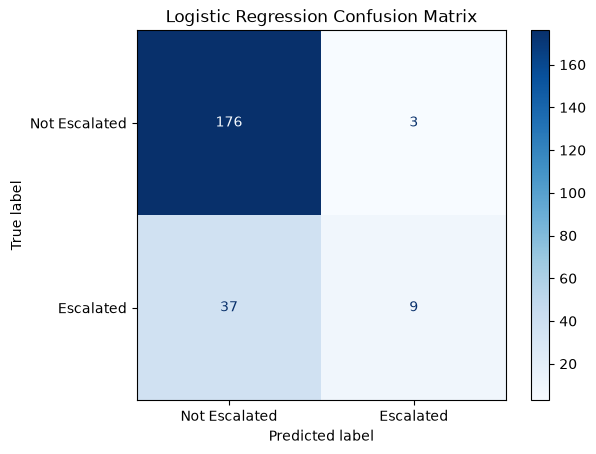

In [32]:
#12
lr_model = trained_models["Logistic Regression"]

y_pred_lr = lr_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Escalated", "Escalated"]
).plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

ROC-AUC: 0.8111488948263298


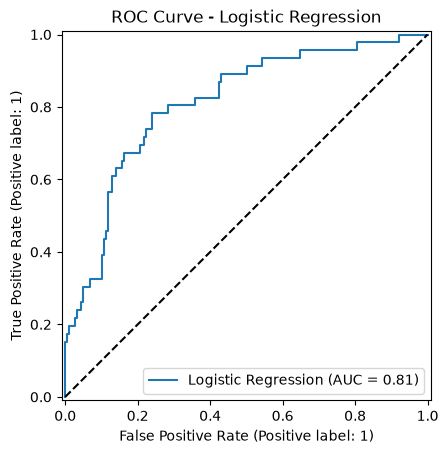

In [33]:

#13
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob_lr)

print("ROC-AUC:", auc)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_lr,
    name="Logistic Regression"
)

plt.plot([0, 1], [0, 1], "k--")

plt.title("ROC Curve - Logistic Regression")
plt.show()

In [34]:
#14
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob_lr >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold
    ).ravel()

    precision = precision_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    cost = 5 * fn + fp

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "FP": fp,
        "FN": fn,
        "Total Cost": cost
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,FP,FN,Total Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230


In [35]:
#15
best_threshold_row = threshold_df.loc[
    threshold_df["Total Cost"].idxmin()
]

print("Best Threshold:")
print(best_threshold_row["Threshold"])

print("\nMinimum Cost:")
print(best_threshold_row["Total Cost"])

print("\nFull Details:")
display(best_threshold_row.to_frame())

Best Threshold:
0.2

Minimum Cost:
98.0

Full Details:


,0
Threshold,0.200000
Precision,0.428571
Recall,0.782609
F1,0.553846
FP,48.000000
FN,10.000000
Total Cost,98.000000


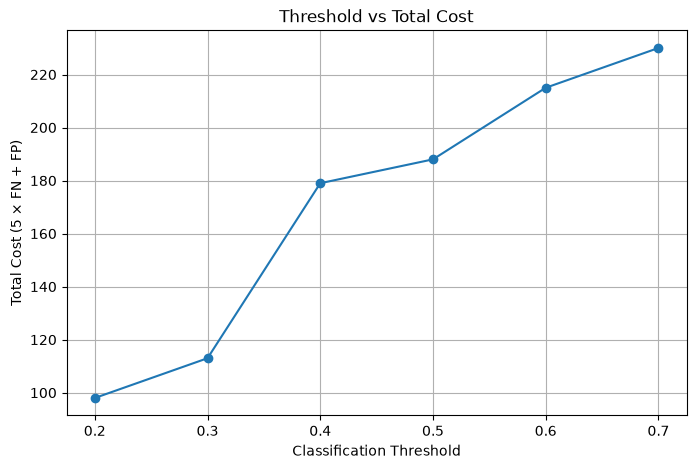

In [36]:

#16
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Total Cost"],
    marker="o"
)

plt.title("Threshold vs Total Cost")
plt.xlabel("Classification Threshold")
plt.ylabel("Total Cost (5 × FN + FP)")
plt.grid(True)

plt.show()

In [ ]:
#17
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

param_grid = {
    "classifier__n_neighbors": [5, 9, 15, 21, 31]
}

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best k:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1:")
print(grid_search.best_score_)

In [ ]:
#18
best_knn = grid_search.best_estimator_

y_pred_knn = best_knn.predict(X_test)

y_prob_knn = best_knn.predict_proba(X_test)[:, 1]

print("Tuned k-NN Performance")

print("Accuracy:",
      accuracy_score(y_test, y_pred_knn))

print("Precision:",
      precision_score(y_test, y_pred_knn, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred_knn, zero_division=0))

print("F1:",
      f1_score(y_test, y_pred_knn, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

In [ ]:
#19
p = 0.30

false_positive_cost = 1
false_negative_cost = 5

# Expected cost of escalating
cost_escalate = (1 - p) * false_positive_cost

# Expected cost of not escalating
cost_not_escalate = p * false_negative_cost

print("Cost of escalating:", cost_escalate)

print("Cost of not escalating:", cost_not_escalate)

# Cost-sensitive threshold
threshold = (
    false_positive_cost /
    (false_positive_cost + false_negative_cost)
)

print("Cost-sensitive threshold:", threshold)

1. Why is accuracy alone potentially misleading?
Accuracy can be misleading when a dataset is imbalanced. In this dataset approximately 79.33% of tickets are not escalated. A model that predicts every ticket as not escalated can achieve 79.33% accuracy but cannot identify any escalated tickets. So precision, recall, F1-score, and ROC-AUC are also necessary.

2. Which classifier has the strongest recall, precision, and F1?
Highest Recall: Logistic Regression — 0.1957 (19.57%).
Highest Precision: Logistic Regression — 0.7500 (75%).
Highest F1-score: Logistic Regression — 0.3103 (31.03%).

3. What changes when the threshold is lowered?
Recall generally increases.
False negatives generally decrease.
False positives generally increase.
Precision may decrease.

4. Which threshold minimizes the cost?
cost=5(FN)+FP
    =5(10)+48=98
the threshold of 0.20 minimizes the cost, with a total cost of 98.

5. Explain prior, likelihood, posterior, and evidence.
Using the ticket escalation scenario:
 Prior: The probability that a ticket will be escalated before considering its features. In this dataset, it is 20.67%.
 Likelihood: The probability of observing particular ticket features, assuming that the ticket is escalated.
 Evidence: The overall probability of observing those ticket features, regardless of whether the ticket is escalated.
 Posterior: The updated probability that a ticket will be escalated after considering its features.


6. With posterior probability 0.30, compare expected costs.
Probability of escalation = 0.30
False positive cost = 1
False negative cost = 5

cost of escalating= (1-0.30) * 1=0.70
Cost of not escalating= 0.30 * 5=1.50
cost-sensitive threshold T= CFP/(CFP + CFN)=1/1+5=0.1667

7. Which model would you recommend for deployment?
I recommend Logistic Regression as the initial candidate for deployment because it achieved 
the highest recall (0.1957), precision (0.7500), and F1-score (0.3103) among the four
evaluated classifiers. It also produces probability estimates, allowing the classification
threshold to be adjusted according to the cost of mistakes.

-Write a 300–500 word recommendation explaining model choice, threshold, error costs,
limitations, and responsible-use risks.
    
The objective of this experiment was to develop binary classification models to predict
whether a service ticket would be escalated. The dataset contained 900 instances, of 
which 186 were escalated. By this class imbalance, accuracy alone is not sufficient
to evaluate model performance.

Four classifiers were evaluated: Majority-Class Baseline, Logistic Regression, Linear 
Discriminant Analysis, and k-Nearest Neighbors with k=15. The models were compared using
accuracy, precision, recall, F1-score, and ROC-AUC. Logistic Regression achieved the 
highest recall (0.1957), precision (0.7500), and F1-score (0.3103). These metrics are 
important because the main objective is to identify escalated tickets ratherthan simply
predict the majority class.

Logistic Regression was selected for further threshold evaluation because it provides 
probability estimates and is relatively interpretable. Six thresholds between 0.20 and 
0.70 were tested. Lowering the classification threshold generally increases recall because
more tickets are predicted as escalated. but this can also increase false positives.

Missing an escalated ticket is five times more costly than unnecessarily escalating a
non-escalated ticket. Therefore, the cost function was defined as 5FN + FP.The threshold of
0.20 produced the lowest test-set cost of 98, with 48 false positivesand 10 false negatives.
At this threshold, precision was 0.4286 and recall was 0.7826.Thisdemonstrates a 
stronger ability to identify escalated tickets, although more non-escalated tickets 
are incorrectly flagged. However, selecting the threshold using the test set may 
produce optimistic results.

The k-NN model was also optimized using stratified five-fold cross-validation. 
Its best value of k was 5, with a cross-validation F1-score of 0.2433.

There are several limitations. The dataset is synthetic and may not represent real
customer-support environments. The number of escalated examples is relatively small,
and model performance may change when real-world ticket patterns differ.

Before deployment, the model should be tested using independent real-world data.
Probability calibration, subgroup performance, and prediction stability should
also be evaluated. Human oversight should remain available for important escalation 
decisions.

I recommend Logistic Regression with a threshold of 0.20 as an initial 
candidate for further testing, subject to independent validation before operational 
deployment